## FASE 0: Setup e Configurazione dell'Ambiente
In questa fase iniziale prepariamo l'ambiente di lavoro. Nello specifico:
- **Installazione**: Ci assicuriamo che le librerie per la lettura di file Excel (incluso il formato binario `.xlsb`) siano presenti.
- **Importazione Librerie**: Importiamo i principali pacchetti per la manipolazione dati (`pandas`, `numpy`), visualizzazione (`matplotlib`, `seaborn`) e analisi statistica dei trend (`scipy.stats`).
- **Configurazione**: Impostiamo le opzioni di visualizzazione per esplorare agevolmente dataset con molte colonne.
- **Percorsi**: Centralizziamo le directory dei file sorgente (Dataset aziendale, Anagrafica ATECO) e della cartella di output per favorire la gestione del codice.

In [1]:
%pip install -q pyxlsb openpyxl

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import theilslopes, kendalltau

# Configurazione opzioni di visualizzazione Pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# --- DEFINIZIONE PERCORSI FILE ---
# Il notebook funziona sia lanciato dalla cartella principale del progetto (es. Google Colab),
# sia dalla cartella 'notebook/' (es. Jupyter o VS Code): la cartella 'data/' viene cercata nei due punti.
BASE_DIR = Path('.') if Path('data').is_dir() else Path('..')
DATA_DIR = BASE_DIR / 'data'
OUTPUT_DIR = BASE_DIR / 'output'

PATH_ATECO = DATA_DIR / 'ATECO.xlsb'
PATH_DATASET = DATA_DIR / 'dataset.csv'
PATH_EXPORT = OUTPUT_DIR / 'dataset_analisi_completa.xlsx'

## FASE 1: Caricamento Dati e Controlli Preliminari
In questa sezione importiamo fisicamente i dati in memoria trasformandoli in DataFrame Pandas.
- **File ISTAT (ATECO)**: Carichiamo il file ufficiale delle attività economiche.
- **Dataset Aziendale**: Importiamo lo storico transazionale e anagrafico dei clienti. Il file viene letto senza la conversione automatica dei testi in valori mancanti: la sigla `NA` (Napoli, 500 clienti) verrebbe altrimenti scambiata per un dato assente. Restano mancanti solo le celle vuote.
- **Validazione**: Stampiamo la dimensione (numero di righe e colonne) per verificare che l'acquisizione sia andata a buon fine e visualizziamo un'anteprima dei dati per familiarizzare con la loro struttura grezza.

In [3]:
for percorso in (PATH_ATECO, PATH_DATASET):
    if not percorso.exists():
        raise FileNotFoundError(
            f"File mancante: {percorso}. Inserirlo nella cartella 'data/' (vedi README)."
        )

# 1. Caricamento file ufficiale ATECO
df_ateco = pd.read_excel(PATH_ATECO, engine='pyxlsb')
print(f"[OK] ATECO caricato: {df_ateco.shape[0]} righe, {df_ateco.shape[1]} colonne")

# 2. Caricamento dataset aziendale
# keep_default_na=False: evita che la sigla provincia 'NA' (Napoli) sia letta come valore mancante;
# na_values=['']: restano mancanti solo le celle vuote
df_dataset = pd.read_csv(PATH_DATASET, encoding='latin1', sep=';', keep_default_na=False, na_values=[''])
print(f"[OK] Dataset aziendale caricato: {df_dataset.shape[0]} righe, {df_dataset.shape[1]} colonne")

# 3. Ispezione veloce
print("\n--- Anteprima ATECO ---")
print(df_ateco.head(3))

print("\n--- Struttura Dataset Aziendale ---")
print("Colonne anagrafiche:", [c for c in df_dataset.columns if not c.startswith('M-')])
print("Colonne mensili:", len([c for c in df_dataset.columns if c.startswith('M-')]))

[OK] ATECO caricato: 3157 righe, 5 colonne
[OK] Dataset aziendale caricato: 20436 righe, 42 colonne

--- Anteprima ATECO ---
  Codice ISTAT                                  Descrizione ISTAT  \
0            A                  AGRICOLTURA, SILVICOLTURA E PESCA   
1           01  COLTIVAZIONI AGRICOLE E PRODUZIONE DI PRODOTTI...   
2         01.1    COLTIVAZIONE DI COLTURE AGRICOLE NON PERMANENTI   

  Codice Completo Codice Dotless  Codice REA (solo num)  
0               A              A                    NaN  
1            A.01            A01                    1.0  
2          A.01.1           A011                   11.0  

--- Struttura Dataset Aziendale ---
Colonne anagrafiche: ['ATECO', 'ATECO_Desc', 'Natura', 'Fatturato', 'Dipendenti', 'Provincia']
Colonne mensili: 36


## FASE 2: Pulizia e Standardizzazione Codici ATECO
L'anagrafica ATECO è cruciale per le analisi di settore. Qui risolviamo i problemi di integrità dei dati per permettere un *join* accurato:
1. **Gestione Valori Mancanti**: I codici `ND` o nulli nel dataset aziendale vengono isolati e riclassificati con un codice fittizio `XXX`.
2. **Standardizzazione Lunghezze**: I codici ISTAT presentano spesso troncature (es. `A.01`). Li riportiamo alla forma canonica di 10 caratteri aggiungendo gli zeri mancanti.
3. **Omologazione Descrizioni**: Creiamo una descrizione unificata incrociando i dati aziendali con il dizionario ufficiale ISTAT.
4. **Macro Categorie**: Estraiamo la macro-area economica (la prima lettera alfabetica del codice, da A a U) utile per raggruppamenti di alto livello.
5. **Descrizione Unica per Codice**: Alcuni codici ATECO compaiono nel dataset con descrizioni scritte in modo diverso (refusi, punteggiatura, livello gerarchico ISTAT). Per questi soli codici adottiamo una descrizione unica (quella ISTAT più specifica), altrimenti le aggregazioni per settore spezzerebbero lo stesso codice in più righe. Le altre descrizioni restano invariate, salvo la rimozione degli spazi superflui a inizio e fine testo.


In [4]:
# 1. Gestione valori mancanti e 'ND' in df_dataset
nd_mask = (df_dataset['ATECO'] == 'ND') | (df_dataset['ATECO'].isna())
df_dataset.loc[nd_mask, 'ATECO'] = 'XXX'
df_dataset.loc[nd_mask, 'ATECO_Desc'] = 'XXX'
df_dataset['ATECO_Desc'] = df_dataset['ATECO_Desc'].fillna('XXX')
print(f"[OK] Record aziendali con ATECO mancante/ND riclassificati in 'XXX': {nd_mask.sum()}")

# 2. Standardizzazione lunghezza codici in df_ateco (padding a 10 caratteri)
df_ateco['ateco_confronto'] = df_ateco['Codice Completo'].astype(str)
padding_rules = {
    9: '0',
    7: '.00',
    6: '0.00',
    4: '.00.00',
    1: '.00.00.00'
}
for length, pad_str in padding_rules.items():
    mask = df_ateco['ateco_confronto'].str.len() == length
    df_ateco.loc[mask, 'ateco_confronto'] = df_ateco.loc[mask, 'ateco_confronto'] + pad_str

print(f"[OK] Codici ATECO standardizzati a 10 caratteri: {(df_ateco['ateco_confronto'].str.len() == 10).sum()} su {len(df_ateco)}")

# 3. Allineamento descrizioni e creazione 'descrizione_omologata'
# Rimuoviamo punteggiatura e normalizziamo in minuscolo per il matching
df_dataset['ATECO_Desc_pulita'] = df_dataset['ATECO_Desc'].astype(str).str.replace(r'[.,"-]', '', regex=True).str.strip().str.lower()
df_ateco['Descrizione_ISTAT_pulita'] = df_ateco['Descrizione ISTAT'].astype(str).str.replace(r'[.,"-]', '', regex=True).str.strip().str.lower()

df_dataset_len10 = df_dataset[df_dataset['ATECO'].str.len() == 10].drop_duplicates(subset=['ATECO', 'ATECO_Desc_pulita'])
df_ateco_unique = df_ateco.drop_duplicates(subset=['ateco_confronto', 'Descrizione_ISTAT_pulita'])

merged_desc = pd.merge(
    df_dataset_len10[['ATECO', 'ATECO_Desc_pulita']],
    df_ateco_unique[['ateco_confronto', 'Descrizione ISTAT', 'Descrizione_ISTAT_pulita']],
    left_on=['ATECO', 'ATECO_Desc_pulita'],
    right_on=['ateco_confronto', 'Descrizione_ISTAT_pulita'],
    how='inner'
)

# Creiamo la mappatura e compiliamo la nuova colonna. Fallback sulla descrizione originale se non c'è match.
match_dict = merged_desc.drop_duplicates('ateco_confronto').set_index('ateco_confronto')['Descrizione ISTAT']
df_ateco['descrizione_omologata'] = df_ateco['ateco_confronto'].map(match_dict).fillna(df_ateco['Descrizione ISTAT'])
print("[OK] Colonna 'descrizione_omologata' generata.")

# 4. Estrazione Macro Categorie (prima lettera)
df_ateco['Macro_Categ_code'] = df_ateco['Codice Completo'].astype(str).str[0]
macro_map = df_ateco[df_ateco['Codice Completo'] == df_ateco['Macro_Categ_code']].set_index('Macro_Categ_code')['Descrizione ISTAT'].to_dict()
df_ateco['Macro_Categ'] = df_ateco['Macro_Categ_code'].map(macro_map)
print("[OK] Macro Categorie estratte e mappate.")

# 5. Descrizione unica per i codici ATECO con più descrizioni
# Si interviene solo sui codici che compaiono nel dataset con descrizioni diverse; tutti gli altri restano invariati.
# Per questi codici si usa la voce ISTAT più specifica (Codice Completo più lungo) tra quelle che, portate a 10 caratteri,
# coincidono col codice. Se il codice non è presente nel dizionario ISTAT, si usa la descrizione più frequente nel dataset.
# Rimuoviamo gli spazi superflui a inizio/fine descrizione: evitano falsi duplicati (es. 'X' e 'X ')
df_dataset['ATECO_Desc'] = df_dataset['ATECO_Desc'].str.strip()

desc_per_codice = df_dataset.groupby('ATECO')['ATECO_Desc'].nunique()
codici_multi = desc_per_codice[desc_per_codice > 1].index

desc_istat = (
    df_ateco.assign(_lung=df_ateco['Codice Completo'].astype(str).str.len())
    .sort_values('_lung')
    .drop_duplicates('ateco_confronto', keep='last')
    .set_index('ateco_confronto')['Descrizione ISTAT']
    .str.strip()
)

def descrizione_piu_frequente(serie):
    conteggi = serie.value_counts()
    return sorted(conteggi[conteggi == conteggi.max()].index)[0]

desc_dataset = df_dataset.groupby('ATECO')['ATECO_Desc'].agg(descrizione_piu_frequente)

mask_multi = df_dataset['ATECO'].isin(codici_multi)
df_dataset.loc[mask_multi, 'ATECO_Desc'] = (
    df_dataset.loc[mask_multi, 'ATECO'].map(desc_istat)
    .fillna(df_dataset.loc[mask_multi, 'ATECO'].map(desc_dataset))
)
print(f"[OK] Codici ATECO con più descrizioni, unificate in una sola: {len(codici_multi)} ({mask_multi.sum()} clienti coinvolti)")

# Pulizia colonne di servizio temporanee
df_dataset.drop(columns=['ATECO_Desc_pulita'], inplace=True, errors='ignore')
df_ateco.drop(columns=['Descrizione_ISTAT_pulita'], inplace=True, errors='ignore')

print("\n--- Anteprima df_ateco arricchito ---")
print(df_ateco[['ateco_confronto', 'descrizione_omologata', 'Macro_Categ']].head())

[OK] Record aziendali con ATECO mancante/ND riclassificati in 'XXX': 403
[OK] Codici ATECO standardizzati a 10 caratteri: 3157 su 3157
[OK] Colonna 'descrizione_omologata' generata.
[OK] Macro Categorie estratte e mappate.
[OK] Codici ATECO con più descrizioni, unificate in una sola: 23 (1102 clienti coinvolti)

--- Anteprima df_ateco arricchito ---
  ateco_confronto                              descrizione_omologata  \
0      A.00.00.00                  AGRICOLTURA, SILVICOLTURA E PESCA   
1      A.01.00.00  COLTIVAZIONI AGRICOLE E PRODUZIONE DI PRODOTTI...   
2      A.01.10.00    COLTIVAZIONE DI COLTURE AGRICOLE NON PERMANENTI   
3      A.01.11.00  Coltivazione di cereali (escluso il riso), leg...   
4      A.01.11.10          Coltivazione di cereali (escluso il riso)   

                         Macro_Categ  
0  AGRICOLTURA, SILVICOLTURA E PESCA  
1  AGRICOLTURA, SILVICOLTURA E PESCA  
2  AGRICOLTURA, SILVICOLTURA E PESCA  
3  AGRICOLTURA, SILVICOLTURA E PESCA  
4  AGRICOLTURA, SILV

## FASE 3: Pulizia Province e Normalizzazione Valori Geografici
Un'analisi territoriale accurata richiede sigle provinciali valide. In questo step:
- Mappiamo e correggiamo le province accorpate o rinominate nel tempo (es. Olbia-Tempio `OT` in Sassari `SS`, Pesaro `PS` in `PU`).
- Gestiamo le casistiche internazionali o speciali (come il Canton Ticino `TI` o Escursionisti Esteri `EE`) riconducendole alla voce `Estero`.
- Uniformiamo i campi geografici assenti o non valorizzati (`prov_non_definite`).

In [5]:
# Definizione del dizionario di sostituzione per le province
sostituzioni_province = {
    'OT': 'SS',       # Olbia-Tempio accorpata a Sassari
    'CI': 'SU',       # Carbonia-Iglesias accorpata a Sud Sardegna
    'TI': 'Estero',   # Canton Ticino (Svizzera)
    'EE': 'Estero',   # Escursionisti Esteri
    'FO': 'FC',       # Forlì diventata Forlì-Cesena
    'PS': 'PU',       # Pesaro diventata Pesaro e Urbino
    'prov_assente': 'prov_non_definite'
}

# Applicazione delle sostituzioni e gestione dei valori nulli
df_dataset['Provincia'] = df_dataset['Provincia'].replace(sostituzioni_province).fillna('prov_non_definite')

# Stampa di verifica dei risultati
print("--- VERIFICA PULIZIA PROVINCE ---")
print(f"Record con provincia 'prov_non_definite': {(df_dataset['Provincia'] == 'prov_non_definite').sum()}")
print(f"Numero totale di province distinte (incluso Estero e non_definite): {df_dataset['Provincia'].nunique()}")

print("\n--- Top 10 Province nel Dataset ---")
print(df_dataset['Provincia'].value_counts().head(10))


--- VERIFICA PULIZIA PROVINCE ---
Record con provincia 'prov_non_definite': 3000
Numero totale di province distinte (incluso Estero e non_definite): 109

--- Top 10 Province nel Dataset ---
Provincia
prov_non_definite    3000
RM                   1719
MI                   1572
FI                    801
TO                    616
MO                    540
NA                    500
BO                    416
TV                    402
RE                    364
Name: count, dtype: int64


## FASE 4: Pulizia Variabili Quantitative e Ricostruzione Ricavi
I dati finanziari grezzi necessitano di attenzione particolare prima di essere utilizzati per segmentare i clienti:
- **Pulizia Dipendenti**: Assicuriamo che la colonna `Dipendenti` contenga solo valori numerici validi, sostituendo eventuali stringhe anomale con `0`.
- **Fatturato dichiarato e Ricavo (`m_sum`)**: la colonna `Fatturato` è il fatturato dichiarato dal cliente: non è affidabile (lo verifichiamo con alcuni controlli di coerenza) e comunque non misura quanto il cliente genera per l'azienda. Lo escludiamo dalle analisi e ricostruiamo il ricavo generato per l'azienda sommando lo storico mensile (da `M-0` a `M-35`) in `m_sum`; la dimensione aziendale è misurata con `Dipendenti`.
- **Gestione Resi/Note di Credito**: Analizziamo i valori negativi nei mesi contabili per tracciare il fenomeno, verificando che non inficino il ricavo totale dell'azienda.

In [6]:
# 1. Verifica stringhe anomale nel dataset originale per Dipendenti e Fatturato
non_num_dip = df_dataset[pd.to_numeric(df_dataset['Dipendenti'], errors='coerce').isna()]['Dipendenti'].unique()
non_num_fatt = df_dataset[pd.to_numeric(df_dataset['Fatturato'], errors='coerce').isna()]['Fatturato'].unique()

print("--- VALORI ORIGINALI CHE VENGONO SOSTITUITI CON 0 ---")
print(f"Stringhe anomale in 'Dipendenti': {non_num_dip}")
print(f"Stringhe anomale in 'Fatturato': {non_num_fatt}")

# 2. Conversione e gestione valori
df_dataset['Dipendenti'] = pd.to_numeric(df_dataset['Dipendenti'], errors='coerce').fillna(0)
df_dataset['Fatturato'] = pd.to_numeric(df_dataset['Fatturato'], errors='coerce').fillna(0)

# 3. Analisi dei valori negativi (Resi / Note di Credito) nelle colonne M-xx
m_cols = [col for col in df_dataset.columns if col.startswith('M-')]
negative_mask = df_dataset[m_cols] < 0
tot_negative = negative_mask.sum().sum()
aziende_con_resi = negative_mask.any(axis=1).sum()

# Calcoliamo il Ricavo come somma delle colonne M-xx e lo salviamo in 'm_sum'
df_dataset['m_sum'] = df_dataset[m_cols].sum(axis=1)

# Controllo per verificare che la somma totale per azienda non sia mai negativa
aziende_con_somma_negativa = (df_dataset['m_sum'] < 0).sum()

print("\n--- ANALISI VALORI NEGATIVI (RESI/NOTE DI CREDITO) IN M-xx ---")
print(f"Celle totali con valori negativi: {tot_negative}")
print(f"Aziende che presentano almeno un reso: {aziende_con_resi} su {len(df_dataset)}")
print(f"Aziende con ricavo totale negativo: {aziende_con_somma_negativa} su {len(df_dataset)}")

# 4. Statistiche descrittive
print("\n--- STATISTICHE DESCRITTIVE (m_sum vs Dipendenti vs Fatturato) ---")
print(df_dataset[['m_sum', 'Dipendenti', 'Fatturato']].describe().drop(index=['min', 'max']).round(2))

# 5. Affidabilità del fatturato dichiarato (Fatturato)
fatt, dip = df_dataset['Fatturato'], df_dataset['Dipendenti']
ricavo_ultimi_12m = df_dataset[[f'M-{i}' for i in range(12)]].sum(axis=1)
fatt_per_dip = (fatt / dip)[(fatt > 0) & (dip > 0)]

print("\n--- AFFIDABILITA' DEL FATTURATO DICHIARATO ---")
print(f"Clienti con Fatturato pari a 0 o mancante: {(fatt == 0).sum()} su {len(df_dataset)} ({(fatt == 0).mean():.1%}), tutti con ricavi verso l'azienda")
print(f"Di cui con dipendenti in organico: {((fatt == 0) & (dip > 0)).sum()}")
print(f"Fatturato per dipendente: mediana {fatt_per_dip.median():,.0f} €; sopra 5 milioni per dipendente: {(fatt_per_dip > 5e6).sum()} clienti")
print(f"Clienti con un fatturato dichiarato inferiore a quanto hanno speso con noi nell'ultimo anno: {((fatt > 0) & (fatt < ricavo_ultimi_12m)).sum()}")
print(f"Correlazione (Spearman) tra Fatturato e ricavo verso l'azienda: {fatt.corr(df_dataset['m_sum'], method='spearman'):.2f}")
print(f"Correlazione (Spearman) tra Fatturato e Dipendenti: {fatt.corr(dip, method='spearman'):.2f} (la relazione esiste, ma con molte eccezioni)")

# 6. Conclusione di Business
print("\n[!] CONCLUSIONE DI BUSINESS SUI RICAVI:")
print("Il fatturato dichiarato dal cliente non è affidabile e non misura il valore del cliente per l'azienda: è escluso dalle analisi.")
print("Il ricavo generato per l'azienda è calcolato sommando i valori mensili (M-0/M-35) e salvato in 'm_sum'.")
print("Nelle analisi successive utilizzeremo 'm_sum' come misura del valore del cliente e 'Dipendenti' come proxy della dimensione aziendale.")


--- VALORI ORIGINALI CHE VENGONO SOSTITUITI CON 0 ---
Stringhe anomale in 'Dipendenti': []
Stringhe anomale in 'Fatturato': []

--- ANALISI VALORI NEGATIVI (RESI/NOTE DI CREDITO) IN M-xx ---
Celle totali con valori negativi: 155
Aziende che presentano almeno un reso: 143 su 20436
Aziende con ricavo totale negativo: 0 su 20436

--- STATISTICHE DESCRITTIVE (m_sum vs Dipendenti vs Fatturato) ---
            m_sum  Dipendenti    Fatturato
count    20436.00    20436.00     20436.00
mean     16520.52       21.34   3814558.63
std     100757.58      159.47   7999604.12
25%         76.00        1.00         0.00
50%        748.00        4.00    521748.00
75%       5543.50       15.00   3275647.25

--- AFFIDABILITA' DEL FATTURATO DICHIARATO ---
Clienti con Fatturato pari a 0 o mancante: 6037 su 20436 (29.5%), tutti con ricavi verso l'azienda
Di cui con dipendenti in organico: 5232
Fatturato per dipendente: mediana 190,604 €; sopra 5 milioni per dipendente: 70 clienti
Clienti con un fatturato dic

### Visualizzazione Asimmetria: Distribuzione dei Ricavi (m_sum)
Confrontiamo la distribuzione in scala lineare e logaritmica per evidenziare la presenza di forti outlier (aziende altospendenti) che sbilanciano la media verso destra. I grafici escludono lo 0,5% di clienti con il ricavo più alto, per non mostrare valori individuali.

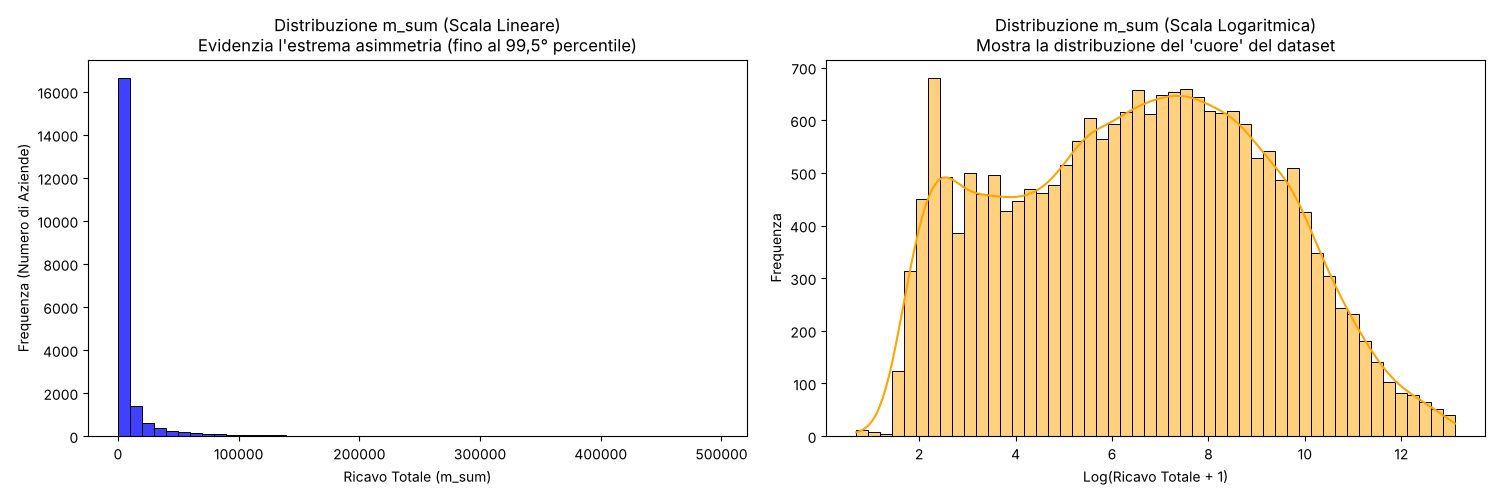

In [7]:
# Per non mostrare valori individuali, i grafici escludono lo 0,5% di clienti con il ricavo più alto
limite = df_dataset['m_sum'].quantile(0.995)
m_sum_plot = df_dataset.loc[df_dataset['m_sum'] <= limite, 'm_sum']

# Creazione della figura con due subplot affiancati
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Istogramma in scala lineare (evidenzia l'asimmetria e gli outlier)
sns.histplot(m_sum_plot, bins=50, ax=axes[0], color='blue', kde=False)
axes[0].set_title("Distribuzione m_sum (Scala Lineare)\nEvidenzia l'estrema asimmetria (fino al 99,5° percentile)")
axes[0].set_xlabel("Ricavo Totale (m_sum)")
axes[0].set_ylabel("Frequenza (Numero di Aziende)")

# 2. Istogramma in scala logaritmica (permette di vedere il "grosso" della distribuzione)
# Usiamo np.log1p per evitare problemi con eventuali zeri (calcola log(1 + x))
sns.histplot(np.log1p(m_sum_plot), bins=50, ax=axes[1], color='orange', kde=True)
axes[1].set_title("Distribuzione m_sum (Scala Logaritmica)\nMostra la distribuzione del 'cuore' del dataset")
axes[1].set_xlabel("Log(Ricavo Totale + 1)")
axes[1].set_ylabel("Frequenza")

plt.tight_layout()
plt.show()


## FASE 5: Metriche Quantitative
Creiamo le variabili fondamentali che guideranno la profilazione comportamentale dei clienti. Le dividiamo in due macro-famiglie:
1. **Metriche Economiche**: Raggruppiamo i ricavi per anni solari relativi (Anno 1: M-35 a M-24, Anno 2: M-23 a M-12, Anno 3: M-11 a M-0) per facilitare confronti annuali.
2. **Metriche Temporali**: Calcoliamo indici di anzianità identificando il primo e l'ultimo mese in cui il cliente ha generato ricavo, i mesi totali in cui è stato attivo e la propensione all'acquisto, misurata come percentuale di mesi attivi sui 36 mesi osservati.

In [8]:
# --- 1. METRICHE ECONOMICHE ---
# Creiamo le liste dei mesi per ogni anno
cols_anno_1 = [f'M-{i}' for i in range(24, 36)] # M-24 a M-35
cols_anno_2 = [f'M-{i}' for i in range(12, 24)] # M-12 a M-23
cols_anno_3 = [f'M-{i}' for i in range(0, 12)]  # M-0 a M-11

# Sommiamo rigorosamente le colonne M-xx
df_dataset['ricavo_anno_1'] = df_dataset[cols_anno_1].sum(axis=1)
df_dataset['ricavo_anno_2'] = df_dataset[cols_anno_2].sum(axis=1)
df_dataset['ricavo_anno_3'] = df_dataset[cols_anno_3].sum(axis=1)


# --- 2. METRICHE TEMPORALI ---
# Ordiniamo le colonne dal più vecchio (M-35) al più recente (M-0)
m_cols_ordered = [f'M-{i}' for i in range(35, -1, -1)]

# Maschera booleana per identificare i mesi con ricavo effettivo (> 0)
mask_active = df_dataset[m_cols_ordered] > 0

# Mesi attivi totali
df_dataset['mesi_attivi'] = mask_active.sum(axis=1)

# Vettore degli offset temporali: [35, 34, ..., 0]
offsets = np.arange(35, -1, -1)

# Matrice dove il valore è l'offset se il mese è attivo, altrimenti NaN
offset_matrix = np.where(mask_active, offsets, np.nan)

# Usiamo nanmax e nanmin per trovare il primo (max offset) e l'ultimo (min offset) mese attivo
# Disattiviamo temporaneamente i warning per le aziende con 0 mesi attivi (che daranno NaN)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    df_dataset['primo_mese_offset'] = np.nanmax(offset_matrix, axis=1)
    df_dataset['ultimo_mese_offset'] = np.nanmin(offset_matrix, axis=1)

# Percentuale di mesi attivi sui 36 mesi osservati (0-100): è la base della frequenza d'acquisto
N_MESI = len(m_cols_ordered)
df_dataset['pct_mesi_attivi'] = df_dataset['mesi_attivi'] / N_MESI * 100

# --- NUMERI DI CONTROLLO ---
print("--- NUMERI DI CONTROLLO FASE 5 ---")
print(f"Totale Ricavo Anno 1 (M-24/M-35): {df_dataset['ricavo_anno_1'].sum():,.2f}")
print(f"Totale Ricavo Anno 2 (M-12/M-23): {df_dataset['ricavo_anno_2'].sum():,.2f}")
print(f"Totale Ricavo Anno 3 (M-0/M-11):  {df_dataset['ricavo_anno_3'].sum():,.2f}")
print("-" * 30)
print(f"Media mesi attivi per azienda: {df_dataset['mesi_attivi'].mean():.2f}")
print(f"Media % mesi attivi sui {N_MESI} mesi: {df_dataset['pct_mesi_attivi'].mean():.2f}%")
print(f"Aziende senza alcun acquisto nei 36 mesi: {(df_dataset['mesi_attivi'] == 0).sum()}")
print(f"Aziende attive in tutti i {N_MESI} mesi: {(df_dataset['mesi_attivi'] == N_MESI).sum()}")

# Mostriamo un'anteprima delle feature ingegnerizzate
feature_cols = ['ricavo_anno_1', 'ricavo_anno_2', 'ricavo_anno_3',
                'primo_mese_offset', 'ultimo_mese_offset',
                'mesi_attivi', 'pct_mesi_attivi']
print(df_dataset[feature_cols].describe().drop(index=['min', 'max']).round(2))

--- NUMERI DI CONTROLLO FASE 5 ---
Totale Ricavo Anno 1 (M-24/M-35): 112,314,083.00
Totale Ricavo Anno 2 (M-12/M-23): 106,347,530.00
Totale Ricavo Anno 3 (M-0/M-11):  118,951,777.00
------------------------------
Media mesi attivi per azienda: 16.67
Media % mesi attivi sui 36 mesi: 46.32%
Aziende senza alcun acquisto nei 36 mesi: 0
Aziende attive in tutti i 36 mesi: 3750
       ricavo_anno_1  ricavo_anno_2  ricavo_anno_3  primo_mese_offset  \
count       20436.00       20436.00        20436.0           20436.00   
mean         5495.89        5203.93         5820.7              28.50   
std         49947.63       34981.47        35176.1              10.26   
25%             6.00           0.00            0.0              25.00   
50%           174.00          98.00           79.0              35.00   
75%          1710.25        1401.25         1370.0              35.00   

       ultimo_mese_offset  mesi_attivi  pct_mesi_attivi  
count            20436.00     20436.00         20436.00 

## FASE 6: Segmentazione Comportamentale e Analisi del Trend
Traduciamo le metriche grezze in cluster di business concrete:
1. **Periodo di Vita**: Incrociamo l'anzianità di acquisizione (Vecchi / Recenti) con lo status attuale (Attivi / Persi basandoci sulla latenza di acquisto negli ultimi mesi).
2. **Comportamento Frequenza**: Classifichiamo le abitudini d'acquisto in *Continuativi*, *Scostanti* o *Occasionali* in base alla percentuale di mesi attivi sui 36 mesi osservati (*Continuativi* sopra l'80%, *Occasionali* sotto il 30%, *Scostanti* nel mezzo).
3. **Trend del Ricavo**: Sostituiamo le semplici medie con analisi statistiche robuste (Regressione di Theil-Sen e Tau di Kendall) per identificare scientificamente se un cliente è in *Aumento*, in *Diminuzione* o *Stabile*, al riparo da anomalie (outlier) nei singoli mesi.

In [9]:
print("--- INIZIO FASE 6: SEGMENTAZIONE ---")

# --- 1. PERIODO DI VITA ---
vecchio_mask = df_dataset['primo_mese_offset'] > 9
perso_mask = df_dataset['ultimo_mese_offset'] >= 3

cond_periodo = [
    (vecchio_mask) & (~perso_mask),
    (vecchio_mask) & (perso_mask),
    (~vecchio_mask) & (~perso_mask),
    (~vecchio_mask) & (perso_mask)
]
choices_periodo = ['Vecchi Attivi', 'Vecchi Persi', 'Recenti Attivi', 'Recenti Persi']
df_dataset['periodo_di_vita'] = np.select(cond_periodo, choices_periodo, default='Sconosciuto')

# --- 2. COMPORTAMENTO FREQUENZA ---
cond_freq = [
    df_dataset['pct_mesi_attivi'] > 80,
    df_dataset['pct_mesi_attivi'] < 30,
    (df_dataset['pct_mesi_attivi'] >= 30) & (df_dataset['pct_mesi_attivi'] <= 80)
]
choices_freq = ['Continuativi', 'Occasionali', 'Scostanti']
df_dataset['comportamento_frequenza'] = np.select(cond_freq, choices_freq, default='Sconosciuto')

# --- 3. TREND RICAVO (THEIL-SEN & KENDALL'S TAU) ---
print("Calcolo del trend temporale in corso (potrebbe richiedere 1-2 minuti)...")

m_cols_ordered = [f'M-{i}' for i in range(35, -1, -1)]
x_time = np.arange(36) # [0, 1, 2, ..., 35]

def compute_trend_category(y):
    # 1. Calcola avg_spend (media dei 36 valori)
    avg_spend = np.mean(y)

    # Ottimizzazione: se è tutto 0 o la media è 0, il trend è stabile
    if avg_spend == 0 or np.all(y == 0):
        return 'Stabile', 0.0

    # Calcola pendenza e p_value
    try:
        slope, _, _, _ = theilslopes(y, x_time)
        tau, p_value = kendalltau(x_time, y)
    except Exception:
        return 'Stabile', 0.0

    if np.isnan(p_value):
        return 'Stabile', 0.0

    # Calcola rel_slope grezzo (per logica) e percentuale (per leggibilità)
    rel_slope = slope / np.abs(avg_spend)
    trend_rel_slope_perc = rel_slope * 100

    # 2. Definisci le costanti
    ALPHA = 0.05
    REL_THRESHOLD = 0.02

    # 3-6. Logica condizionale rigorosa
    if p_value > ALPHA:
        category = 'Stabile'
    elif rel_slope > REL_THRESHOLD:
        category = 'Aumento'
    elif rel_slope < -REL_THRESHOLD:
        category = 'Diminuzione'
    else:
        category = 'Stabile'

    return category, trend_rel_slope_perc

# Applichiamo la funzione row-by-row
vals = df_dataset[m_cols_ordered].values
results = [compute_trend_category(row) for row in vals]

# Assegniamo le nuove colonne scorporando i risultati
df_dataset['trend_ricavo'] = [r[0] for r in results]
df_dataset['trend_rel_slope'] = [r[1] for r in results]

print("[OK] Segmentazione e Trend calcolati con successo.")

# Mostriamo le distribuzioni richieste
print("\n--- DISTRIBUZIONE PERIODO DI VITA ---")
print(df_dataset['periodo_di_vita'].value_counts())

print("\n--- DISTRIBUZIONE COMPORTAMENTO FREQUENZA ---")
print(df_dataset['comportamento_frequenza'].value_counts())

print("\n--- DISTRIBUZIONE TREND RICAVO ---")
print(df_dataset['trend_ricavo'].value_counts())

--- INIZIO FASE 6: SEGMENTAZIONE ---
Calcolo del trend temporale in corso (potrebbe richiedere 1-2 minuti)...
[OK] Segmentazione e Trend calcolati con successo.

--- DISTRIBUZIONE PERIODO DI VITA ---
periodo_di_vita
Vecchi Attivi     9543
Vecchi Persi      8822
Recenti Attivi    1463
Recenti Persi      608
Name: count, dtype: int64

--- DISTRIBUZIONE COMPORTAMENTO FREQUENZA ---
comportamento_frequenza
Occasionali     9204
Continuativi    6162
Scostanti       5070
Name: count, dtype: int64

--- DISTRIBUZIONE TREND RICAVO ---
trend_ricavo
Stabile        16301
Diminuzione     2608
Aumento         1527
Name: count, dtype: int64


## FASE 7: Analisi Approfondite (Clienti Persi e Churn)
In questa sezione estraiamo *insight* strategici interrogando i cluster appena creati:
- **Focus Clienti Persi**: Analizziamo la massa di clienti che ha abbandonato, verificandone il trend precedente all'abbandono.
- **Rischio Churn**: Identifichiamo in modo proattivo i clienti ad alto valore (sopra il 75° percentile per fatturato) che mostrano segnali premonitori di abbandono (inattività prolungata da 2, 3 o 4 mesi).
- **Mappe di Contingenza**: Visualizziamo tramite heatmap la distribuzione incrociata dei comportamenti per capire le dinamiche di portafoglio.

--- 1. ANALISI CLIENTI PERSI ---
Totale clienti persi: 9430

Distribuzione trend ricavo sui clienti persi:
trend_ricavo
Stabile        8050
Diminuzione    1367
Aumento          13
Name: count, dtype: int64

--- 2. FUNNEL RISCHIO CHURN ---
Filtro 1 (ricavo_anno_2 >= 75° percentile [1,401]): 5109 clienti
Filtro 2 (Filtro 1 + m_sum > 0): 5109 clienti
Filtro 3a (Filtro 2 + inattivi da >= 2 mesi): 723 clienti a rischio
Filtro 3b (Filtro 2 + inattivi da >= 3 mesi): 631 clienti a rischio
Filtro 3c (Filtro 2 + inattivi da >= 4 mesi): 584 clienti a rischio

--- 3. HEATMAP CONTINGENZA ---


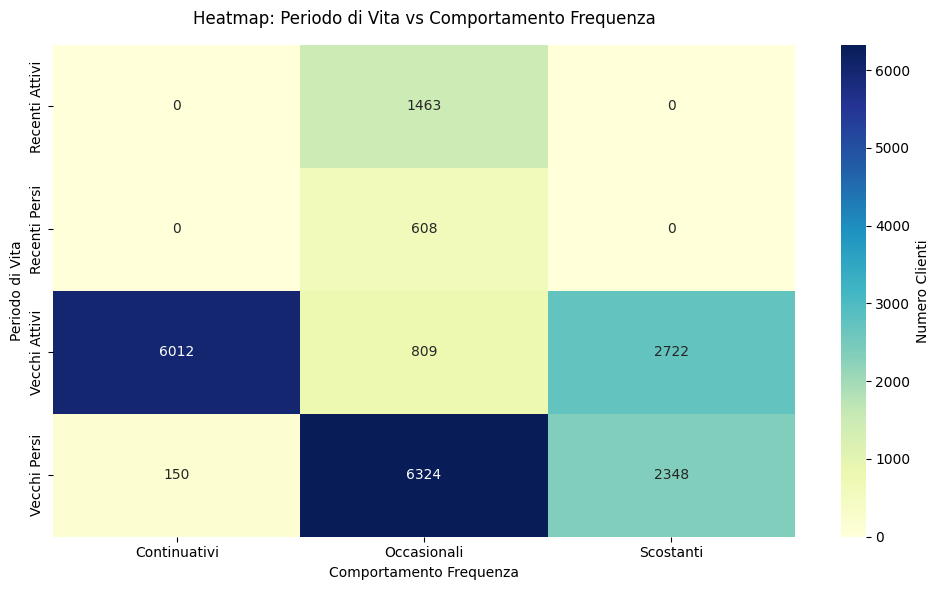

In [10]:
# --- 0. INSERIMENTO COMPANY_ID ---
df_dataset['Company_ID'] = range(1, len(df_dataset) + 1)

print("--- 1. ANALISI CLIENTI PERSI ---")
# Filtriamo per Vecchi Persi e Recenti Persi
persi_mask = df_dataset['periodo_di_vita'].isin(['Vecchi Persi', 'Recenti Persi'])
df_persi = df_dataset[persi_mask]
print(f"Totale clienti persi: {len(df_persi)}")
print("\nDistribuzione trend ricavo sui clienti persi:")
print(df_persi['trend_ricavo'].value_counts())

print("\n--- 2. FUNNEL RISCHIO CHURN ---")
# Filtro 1: ricavo_anno_2 >= 75° percentile
p75_anno2 = df_dataset['ricavo_anno_2'].quantile(0.75)
f1_mask = df_dataset['ricavo_anno_2'] >= p75_anno2
print(f"Filtro 1 (ricavo_anno_2 >= 75° percentile [{p75_anno2:,.0f}]): {f1_mask.sum()} clienti")

# Filtro 2: Filtro 1 AND m_sum > 0
f2_mask = f1_mask & (df_dataset['m_sum'] > 0)
print(f"Filtro 2 (Filtro 1 + m_sum > 0): {f2_mask.sum()} clienti")

# Filtro 3: Nessuna vendita negli ultimi 2, 3 o 4 mesi
# Basato su 'ultimo_mese_offset' (es. >= 2 significa inattivo da almeno 2 mesi)
f3_2mesi = f2_mask & (df_dataset['ultimo_mese_offset'] >= 2)
f3_3mesi = f2_mask & (df_dataset['ultimo_mese_offset'] >= 3)
f3_4mesi = f2_mask & (df_dataset['ultimo_mese_offset'] >= 4)

print(f"Filtro 3a (Filtro 2 + inattivi da >= 2 mesi): {f3_2mesi.sum()} clienti a rischio")
print(f"Filtro 3b (Filtro 2 + inattivi da >= 3 mesi): {f3_3mesi.sum()} clienti a rischio")
print(f"Filtro 3c (Filtro 2 + inattivi da >= 4 mesi): {f3_4mesi.sum()} clienti a rischio")

print("\n--- 3. HEATMAP CONTINGENZA ---")
# Creazione della tabella di contingenza
crosstab_pf = pd.crosstab(df_dataset['periodo_di_vita'], df_dataset['comportamento_frequenza'])

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(crosstab_pf, annot=True, fmt='d', cmap='YlGnBu', cbar_kws={'label': 'Numero Clienti'})
plt.title('Heatmap: Periodo di Vita vs Comportamento Frequenza', pad=15)
plt.ylabel('Periodo di Vita')
plt.xlabel('Comportamento Frequenza')
plt.tight_layout()
plt.show()

## FASE 7B: Segnale di collasso (limite del trend Theil-Sen)
Il trend della Fase 6 misura la pendenza di lungo periodo sui 36 mesi, quindi coglie bene le variazioni graduali. Non coglie i clienti il cui ricavo si concentra in pochi mesi e poi crolla (andamento "a gobba"): la pendenza mediana resta vicina a zero e il cliente risulta Stabile. Inoltre un cliente è Attivo finché ha almeno un mese con ricavo maggiore di zero, anche se si tratta di pochi euro.

Questa fase aggiunge un segnale complementare, **senza modificare le segmentazioni delle fasi precedenti**:
- `var_yoy_perc`: variazione percentuale del ricavo dell'anno 3 rispetto all'anno 2 (per clienti con ricavo anno 2 molto piccolo può assumere valori enormi: va letta insieme al filtro di rilevanza).
- `flag_collasso`: vale 1 se il cliente è rilevante (ricavo anno 2 pari o superiore al 75° percentile, come nel funnel churn) e vale almeno una di queste due condizioni: (a) il ricavo dell'anno 3 è sotto il 50% di quello dell'anno 2; (b) il ricavo degli ultimi 6 mesi è sotto il 5% della sua media semestrale precedente.

Le soglie sono scelte di giudizio, non derivate dai dati: sono parametri modificabili all'inizio della cella. In fondo, un grafico mostra l'andamento mensile complessivo dei clienti segnalati ma classificati *Stabile* e *Attivi*.


--- INIZIO FASE 7B: SEGNALE DI COLLASSO ---
Clienti rilevanti (ricavo anno 2 >= 1,401): 5109
Clienti con segnale di collasso: 1111 (annuo: 1073, recente: 682, entrambi: 644)

--- CLIENTI SEGNALATI: etichetta di trend (Fase 6) ---
trend_ricavo
Diminuzione    660
Stabile        446
Aumento          5
Name: count, dtype: int64

--- CLIENTI SEGNALATI: periodo di vita (Fase 6) ---
periodo_di_vita
Vecchi Persi     598
Vecchi Attivi    513
Name: count, dtype: int64

Clienti 'Stabile' e 'Attivi' con segnale di collasso: 223
Ricavo anno 2 di questi clienti: 8,008,486 | anno 3: 1,883,402


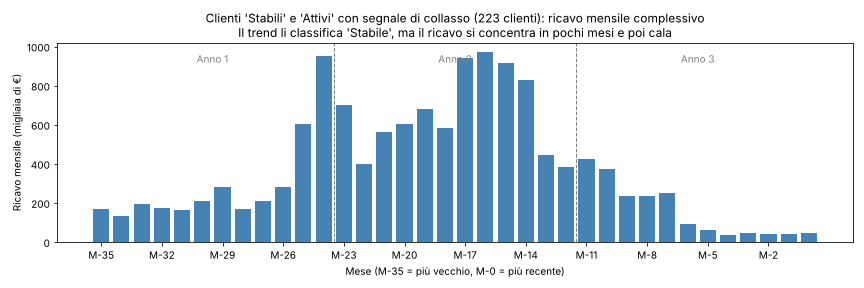

In [11]:
print("--- INIZIO FASE 7B: SEGNALE DI COLLASSO ---")

# --- PARAMETRI (scelte di giudizio, modificabili) ---
SOGLIA_CALO_ANNUO = 0.50   # collasso annuo: ricavo anno 3 sotto il 50% del ricavo anno 2
SOGLIA_RECENTE = 0.05      # collasso recente: ultimi 6 mesi sotto il 5% della media semestrale precedente
# La rilevanza minima riusa p75_anno2 (75° percentile del ricavo anno 2) calcolato nella Fase 7

# --- 1. VARIAZIONE ANNUA (anno 3 vs anno 2) ---
# Vale NaN se il cliente non aveva ricavi nell'anno 2 (variazione non calcolabile)
anno2_valido = df_dataset['ricavo_anno_2'].where(df_dataset['ricavo_anno_2'] > 0)
df_dataset['var_yoy_perc'] = ((df_dataset['ricavo_anno_3'] / anno2_valido - 1) * 100).round(1)

# --- 2. RICAVO RECENTE vs STORICO ---
cols_ultimi_6 = [f'M-{i}' for i in range(5, -1, -1)]         # M-5 ... M-0
cols_precedenti = [f'M-{i}' for i in range(35, 5, -1)]       # M-35 ... M-6 (30 mesi = 5 semestri)
ricavo_ultimi_6 = df_dataset[cols_ultimi_6].sum(axis=1)
media_semestre_prec = df_dataset[cols_precedenti].sum(axis=1) / 5

# --- 3. FLAG DI COLLASSO ---
rilevante = df_dataset['ricavo_anno_2'] >= p75_anno2
calo_annuo = rilevante & (df_dataset['ricavo_anno_3'] < SOGLIA_CALO_ANNUO * df_dataset['ricavo_anno_2'])
calo_recente = rilevante & (media_semestre_prec > 0) & (ricavo_ultimi_6 < SOGLIA_RECENTE * media_semestre_prec)
df_dataset['flag_collasso'] = (calo_annuo | calo_recente).astype(int)

flag = df_dataset['flag_collasso'] == 1
print(f"Clienti rilevanti (ricavo anno 2 >= {p75_anno2:,.0f}): {rilevante.sum()}")
print(f"Clienti con segnale di collasso: {flag.sum()} (annuo: {calo_annuo.sum()}, recente: {calo_recente.sum()}, entrambi: {(calo_annuo & calo_recente).sum()})")

print("\n--- CLIENTI SEGNALATI: etichetta di trend (Fase 6) ---")
print(df_dataset.loc[flag, 'trend_ricavo'].value_counts())

print("\n--- CLIENTI SEGNALATI: periodo di vita (Fase 6) ---")
print(df_dataset.loc[flag, 'periodo_di_vita'].value_counts())

# Clienti che le segmentazioni precedenti presenterebbero come "sani" (Stabili e Attivi) pur avendo il segnale
sfuggiti = flag & (df_dataset['trend_ricavo'] == 'Stabile') & df_dataset['periodo_di_vita'].str.endswith('Attivi')
print(f"\nClienti 'Stabile' e 'Attivi' con segnale di collasso: {sfuggiti.sum()}")
print(f"Ricavo anno 2 di questi clienti: {df_dataset.loc[sfuggiti, 'ricavo_anno_2'].sum():,.0f} | anno 3: {df_dataset.loc[sfuggiti, 'ricavo_anno_3'].sum():,.0f}")

# --- 4. ANDAMENTO COMPLESSIVO DEI CLIENTI SEGNALATI MA "STABILI" E "ATTIVI" ---
profilo_sfuggiti = df_dataset.loc[sfuggiti, m_cols_ordered].sum()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(36), profilo_sfuggiti.values / 1e3, color='steelblue')
for confine in (11.5, 23.5):
    ax.axvline(confine, color='gray', linestyle='--', linewidth=1)
ymax = ax.get_ylim()[1]
for centro, etichetta in ((5.5, 'Anno 1'), (17.5, 'Anno 2'), (29.5, 'Anno 3')):
    ax.text(centro, ymax * 0.95, etichetta, ha='center', va='top', color='gray')
ax.set_xticks(range(0, 36, 3))
ax.set_xticklabels([m_cols_ordered[i] for i in range(0, 36, 3)])
ax.set_title(f"Clienti 'Stabili' e 'Attivi' con segnale di collasso ({int(sfuggiti.sum())} clienti): ricavo mensile complessivo\nIl trend li classifica 'Stabile', ma il ricavo si concentra in pochi mesi e poi cala")
ax.set_xlabel("Mese (M-35 = più vecchio, M-0 = più recente)")
ax.set_ylabel("Ricavo mensile (migliaia di €)")
plt.tight_layout()
plt.show()


## FASE 8: Aggregazioni Dimensionali (Provincia e ATECO)
Dopo aver lavorato a livello di singola azienda (riga), creiamo le viste aggregate necessarie per i report:
1. **Dimensione Geografica (Provincia)**: Aggreghiamo ricavi, clienti totali, attivi e persi per territorio.
2. **Dimensione Micro-Settoriale (ATECO specifico)**: Raggruppiamo i KPI scendendo nel dettaglio del singolo codice ISTAT a 10 cifre (una riga per codice, grazie alla descrizione unica della Fase 2).
3. **Dimensione Macro-Settoriale (Macro Area ATECO)**: Utilizziamo un approccio di *Left Join* sull'anagrafica ufficiale di base per garantire che l'output contenga **sempre** le 21 sezioni principali ISTAT (A-U) più la categoria `X` (NON DEFINITA, per i codici ATECO mancanti), valorizzando a 0 quelle in cui l'azienda non ha clienti (es. Settore T).

In [12]:
print("--- INIZIO FASE 8: AGGREGAZIONI DIMENSIONALI ---")

# Prepariamo un flag numerico per i clienti attivi per facilitare la somma
df_dataset['is_attivo'] = df_dataset['periodo_di_vita'].isin(['Vecchi Attivi', 'Recenti Attivi']).astype(int)

# 1. Aggregazione per Provincia
agg_provincia = df_dataset.groupby('Provincia').agg(
    numero_clienti=('Company_ID', 'nunique'),
    ricavo_totale=('m_sum', 'sum'),
    clienti_attivi=('is_attivo', 'sum')
).reset_index()
agg_provincia['clienti_persi'] = agg_provincia['numero_clienti'] - agg_provincia['clienti_attivi']
agg_provincia['%_attivi'] = (agg_provincia['clienti_attivi'] / agg_provincia['numero_clienti'] * 100).round(1)
agg_provincia = agg_provincia.sort_values('ricavo_totale', ascending=False)

# 2. Aggregazione per Settore ATECO (Micro)
# Ci assicuriamo che Macro_Categ_code sia presente e derivato correttamente per tutti gli ATECO, incluso 'XXX'.
if 'Macro_Categ_code' not in df_dataset.columns:
    df_dataset['Macro_Categ_code'] = df_dataset['ATECO'].astype(str).str[0]
# Impostiamo esplicitamente 'X' per i codici ATECO 'XXX', se non è già stato fatto.
df_dataset.loc[df_dataset['ATECO'].astype(str).str.startswith('XXX'), 'Macro_Categ_code'] = 'X'

# Aggiorniamo macro_map per includere esplicitamente 'X' per 'NON DEFINITA', se non è già presente.
# Questo assicura che, anche se la colonna 'Macro_Categ' esiste, 'X' venga mappato correttamente.
if 'X' not in macro_map:
    macro_map['X'] = 'NON DEFINITA'

# Aggiungiamo la descrizione della Macro Categoria al dataset principale
# Questo utilizzerà la macro_map aggiornata
df_dataset['Macro_Categ'] = df_dataset['Macro_Categ_code'].map(macro_map).fillna('NON DEFINITA')

agg_ateco = df_dataset.groupby(['Macro_Categ_code', 'ATECO', 'ATECO_Desc']).agg(
    numero_clienti=('Company_ID', 'nunique'),
    ricavo_totale=('m_sum', 'sum'),
    clienti_attivi=('is_attivo', 'sum')
).reset_index()
agg_ateco['clienti_persi'] = agg_ateco['numero_clienti'] - agg_ateco['clienti_attivi']
agg_ateco['%_attivi'] = (agg_ateco['clienti_attivi'] / agg_ateco['numero_clienti'] * 100).round(1)
agg_ateco = agg_ateco.sort_values('ricavo_totale', ascending=False)

# 3. Aggregazione per Macro Area ATECO
# [SCELTA DI DESIGN] Utilizziamo una Left Join partendo dall'anagrafica completa (agg_macro_base)
# per garantire che tutte le 22 macro aree siano sempre presenti nel report finale (esportazione Excel),
# anche se alcune (es. la categoria 'T' che ha 0 clienti) non sono rappresentate nel dataset attuale.
agg_macro_base = pd.DataFrame(list(macro_map.items()), columns=['Macro_Categ_code', 'Macro_Categ'])
agg_macro_data = df_dataset.groupby(['Macro_Categ_code', 'Macro_Categ']).agg(
    numero_clienti=('Company_ID', 'nunique'),
    ricavo_totale=('m_sum', 'sum'),
    clienti_attivi=('is_attivo', 'sum')
).reset_index()

agg_macro = pd.merge(agg_macro_base, agg_macro_data, on=['Macro_Categ_code', 'Macro_Categ'], how='left').fillna(0)

agg_macro['clienti_persi'] = agg_macro['numero_clienti'] - agg_macro['clienti_attivi']
# Gestiamo il caso in cui numero_clienti è 0 per evitare divisioni per zero
agg_macro['%_attivi'] = np.where(agg_macro['numero_clienti'] > 0,
                                 (agg_macro['clienti_attivi'] / agg_macro['numero_clienti'] * 100).round(1),
                                 0.0)
agg_macro = agg_macro.sort_values('ricavo_totale', ascending=False)

print(f"Righe df_provincia_analysis: {len(agg_provincia)}")
print(f"Righe df_ateco_analysis (Micro): {len(agg_ateco)}")
print(f"Righe df_macro_area_analysis: {len(agg_macro)}")

--- INIZIO FASE 8: AGGREGAZIONI DIMENSIONALI ---
Righe df_provincia_analysis: 109
Righe df_ateco_analysis (Micro): 1204
Righe df_macro_area_analysis: 22


## FASE 9: Consolidamento, Validazione ed Export
L'ultimo step operativo. Raccogliamo tutto il lavoro svolto per esternalizzarlo:
- **Selezione e Ordinamento**: Filtriamo solo le colonne pulite e utili al business (rimuovendo le variabili temporanee). Il dataset granulare conserva anche i 36 valori mensili, necessari per ricostruire le serie storiche nelle dashboard.
- **Data Quality Assertions**: Eseguiamo test bloccanti (`assert`) per accertarci che nessuna riga sia andata persa o duplicata nel processo di trasformazione, e che il `Company_ID` rimanga un identificatore univoco solido.
- **Generazione Output**: Creiamo un file Excel consolidato strutturato su 6 fogli distinti (Dataset Granulare, Provincia, ATECO Micro, Macro Area, Clienti Persi, Rischio Churn), pronto per essere caricato in strumenti di Data Visualization (es. PowerBI, Tableau, Looker).

In [13]:
print("--- INIZIO FASE 9: EXPORT EXCEL MULTI-FOGLIO ---")

# 1. Dataset clienti (livello riga): colonne di analisi + i 36 valori mensili (serie storica originale)
colonne_export = [
    'Company_ID', 'Provincia', 'ATECO', 'ATECO_Desc', 'Macro_Categ', 'Natura',
    'Dipendenti', 'Fatturato', 'm_sum', 'ricavo_anno_1', 'ricavo_anno_2', 'ricavo_anno_3',
    'mesi_attivi', 'pct_mesi_attivi', 'primo_mese_offset', 'ultimo_mese_offset',
    'periodo_di_vita', 'comportamento_frequenza', 'trend_ricavo', 'trend_rel_slope',
    'var_yoy_perc', 'flag_collasso'
]

df_export = df_dataset[colonne_export + m_cols_ordered].copy()

# 2-4. Le aggregazioni (Provincia, ATECO, Macro) sono pronte dalla Fase 8

# 5. Clienti Persi
df_persi_export = df_dataset[df_dataset['periodo_di_vita'].isin(['Vecchi Persi', 'Recenti Persi'])][colonne_export].copy()

# 6. Clienti a rischio churn (Filtro 3a: ricavo alto, m_sum>0, inattivi da >= 2 mesi)
df_rischio_churn = df_dataset[f3_2mesi][colonne_export].copy()

# --- ASSERTIONS RICHIESTE ---
assert len(df_export) == len(df_dataset), "Errore: Il numero di righe non coincide col dataset originale!"
if 'Company_ID' in df_export.columns:
    assert df_export['Company_ID'].duplicated().sum() == 0, "Errore: Ci sono duplicati in Company_ID!"
else:
    assert df_export.index.duplicated().sum() == 0, "Errore: Ci sono indici/righe duplicate nel dataset finale!"

assert np.allclose(df_export[m_cols_ordered].sum(axis=1), df_export['m_sum']), "Errore: la somma dei 36 mesi non coincide con m_sum!"
assert len(m_cols_ordered) == 36, "Errore: servono esattamente 36 colonne mensili!"

# Stampa dei conteggi righe per i 6 fogli
print("\n--- CONTEGGIO RIGHE PER FOGLIO EXCEL ---")
print(f"1. Dataset Clienti: {len(df_export)}")
print(f"2. Aggregazione Provincia: {len(agg_provincia)}")
print(f"3. Aggregazione ATECO (Micro): {len(agg_ateco)}")
print(f"4. Aggregazione Macro Area: {len(agg_macro)}")
print(f"5. Clienti Persi: {len(df_persi_export)}")
print(f"6. Rischio Churn: {len(df_rischio_churn)}")

# Creazione del file Excel con 6 fogli distinti
print(f"\nEsportazione in corso verso: {PATH_EXPORT} (potrebbe richiedere qualche secondo)...")

OUTPUT_DIR.mkdir(exist_ok=True)
with pd.ExcelWriter(PATH_EXPORT, engine='openpyxl') as writer:
    df_export.to_excel(writer, sheet_name='Dataset Clienti', index=False)
    agg_provincia.to_excel(writer, sheet_name='Aggregazione Provincia', index=False)
    agg_ateco.to_excel(writer, sheet_name='Aggregazione ATECO', index=False)
    agg_macro.to_excel(writer, sheet_name='Aggregazione Macro Area', index=False)
    df_persi_export.to_excel(writer, sheet_name='Clienti Persi', index=False)
    df_rischio_churn.to_excel(writer, sheet_name='Rischio Churn', index=False)

print("[OK] Esportazione multi-foglio completata con successo!")

--- INIZIO FASE 9: EXPORT EXCEL MULTI-FOGLIO ---

--- CONTEGGIO RIGHE PER FOGLIO EXCEL ---
1. Dataset Clienti: 20436
2. Aggregazione Provincia: 109
3. Aggregazione ATECO (Micro): 1204
4. Aggregazione Macro Area: 22
5. Clienti Persi: 9430
6. Rischio Churn: 723

Esportazione in corso verso: output/dataset_analisi_completa.xlsx (potrebbe richiedere qualche secondo)...
[OK] Esportazione multi-foglio completata con successo!
